In [8]:
from typing import List, Callable
from scipy.optimize import approx_fprime, minimize
from scipy.differentiate import hessian

import matplotlib.pyplot as plt
import numpy as np
from timeit import timeit

import sys
sys.path.insert(0, "../")
from visualisation import plot_trajectory_3d_plotly, plot_trajectory
from test_functions import rosenbroke, himmelbau, rostrigin, izom

Vector = List[float]

In [9]:
def function(x: Vector): return 4*x[0]**2 + 4*x[0] + x[1]**2 - 8*x[1] + 5

def condition(x: Vector): return 2*x[0] - x[1] - 6

def penalty_func(x: List[float], func: Callable, r: float, cond: List[Callable]) -> float:
    penalty = 0.0
    
    for g in cond:
        penalty += g(x)**2
        
    return func(x) + (r / 2.0) * penalty

In [10]:
def fine_method(x: Vector, function: Callable, cond:Callable, C = 10.0, eps = 1e-8, r0 = 1.0, max_iter = 1000):
    x_k = np.array(x, dtype=float)
    k = 0
    r_k = r0
    traj = [x.copy()]
    
    # print(f"Старт {x_k}, f(x) = {function(x_k)}")
    
    while k <= max_iter:
        function_to_minimize = lambda x: penalty_func(x, function, r_k, cond)
        
        res = minimize(function_to_minimize, x_k, method="BFGS")
        x_new = res.x
        traj.append(x_new.copy())
        
        diff = np.linalg.norm(x_new - x_k)
        
        if diff <= eps:
            # print("Дело сделано")
            break
            
        x_k = x_new
        r_k *= C
        
        k+=1
        
    return x_k, function(x_k), k-1, traj

In [15]:
%timeit fine_method([100000, -10], function, [condition], eps=1e-12)

117 ms ± 17.3 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
x_func, f_func, k_func, traj_func = fine_method([100000, -10000], function, [condition], eps=1e-12)
print(f"Итога x* == {x_func}, f(x) == {f_func}\n за {k_func} итераций\n путь:{traj_func}")

Итога x* == [ 2.24995489 -1.50009021], f(x) == 48.49999998615029
 за 10 итераций
 путь:[[100000, -10000], array([0.87500008, 1.25000038]), array([ 1.99999991, -1.0000002 ]), array([ 2.22277235, -1.44554441]), array([ 2.24725275, -1.49450548]), array([ 2.2497251, -1.4994499]), array([ 2.2499109 , -1.50006819]), array([ 2.2499505 , -1.50008799]), array([ 2.24995446, -1.50008998]), array([ 2.24995485, -1.50009018]), array([ 2.24995489, -1.5000902 ]), array([ 2.24995489, -1.50009021]), array([ 2.24995489, -1.50009021])]


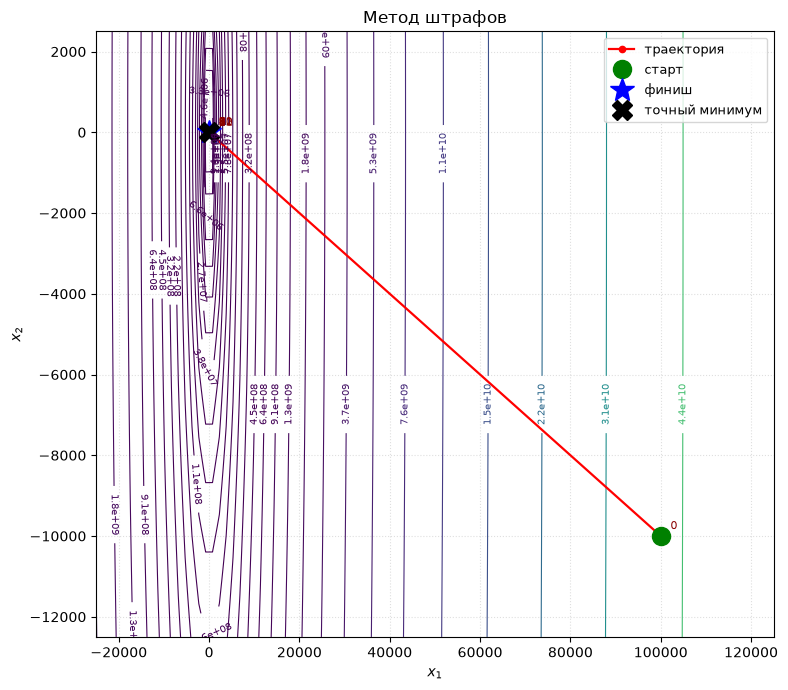

In [18]:
plot_trajectory(function, traj_func, title='Метод штрафов', exact=(2.25, -1.5))

In [14]:
plot_trajectory_3d_plotly(function, traj_func, title='Метод штрафов', exact=(2.25, -1.5))